# A predictive statistical model for $k_La$

This notebook fits your $k_La$ measurements to a second-order polynomial in agitation rate $A$ and gas flow rate $F$:

$$k_La = \beta_0 + \beta_1 A + \beta_2 F + \beta_3 A^2 + \beta_4 F^2 + \beta_5 A F + \varepsilon$$

where $\varepsilon$ is the random error term: the variation in $k_La$ that the model does not explain.

It works through four parts:

1. **Fit** the full second-order model to your data.
2. **Choose** which terms to keep, and refit the model without the others.
3. **Check the goodness of fit** of the model you chose.
4. **Plot** the model and see how much the interaction between agitation and gas flow matters.

**To use it:** put your data file in the same folder as this notebook and fill in the settings cell. Then choose **Run → Run All Cells** from the menu. After changing a setting, run all cells again.

## Settings

The data file needs one row per run, with one column for $k_La$ and one for each factor. Replicate runs at the same condition each get their own row. The column names below must match your file's headers exactly.

In [1]:
DATA_FILE = "kla_data_real_units.csv"

# Column headers in the data file.
RESPONSE = "kLa"
FACTOR_A = "Agitation"
FACTOR_F = "GasFlow"

# Labels for plots and printed results, including units.
RESPONSE_LABEL = "kLa (1/h)"
A_LABEL = "Agitation (rpm)"
F_LABEL = "Gas flow (vvm)"

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f as f_dist, t as t_dist

warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell to match its name exactly.")
df = pd.read_csv(DATA_FILE)
missing_cols = [c for c in (RESPONSE, FACTOR_A, FACTOR_F) if c not in df.columns]
if missing_cols:
    raise KeyError(f"Column(s) {missing_cols} not found. The file's columns are: {list(df.columns)}.")
df = df[[RESPONSE, FACTOR_A, FACTOR_F]].dropna().astype(float)
y, A, F = df[RESPONSE].to_numpy(), df[FACTOR_A].to_numpy(), df[FACTOR_F].to_numpy()

COLUMNS = {"A": lambda a, f: a, "F": lambda a, f: f, "A2": lambda a, f: a**2,
           "F2": lambda a, f: f**2, "AF": lambda a, f: a * f}
SYMBOL = {"A": "A", "F": "F", "A2": "A²", "F2": "F²", "AF": "A·F"}
BETA = {"A": "β1", "F": "β2", "A2": "β3", "F2": "β4", "AF": "β5"}
FULL = ["A", "F", "A2", "F2", "AF"]

# Average kLa and number of runs at each condition.
conditions = df.groupby([FACTOR_A, FACTOR_F])[RESPONSE].agg(["mean", "size"]).reset_index()
cond_mean = df.groupby([FACTOR_A, FACTOR_F])[RESPONSE].transform("mean").to_numpy()
n_runs, n_conditions = len(y), len(conditions)


def design_matrix(a, f, terms):
    return np.column_stack([np.ones_like(a)] + [COLUMNS[t](a, f) for t in terms])


def fit(terms):
    # Least-squares fit of the model with the given terms, plus its p-values and lack-of-fit test.
    X = design_matrix(A, F, terms)
    scaled = X / np.abs(X).max(axis=0)
    if np.linalg.matrix_rank(scaled) < X.shape[1]:
        raise ValueError("Your design cannot separate all the terms in the full model. A second-order model "
                         "needs at least three levels of each factor (low, center and high) and at least six "
                         "distinct conditions. Check your design and your data file.")
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ coef
    p = X.shape[1]
    df_resid = n_runs - p
    ss_resid = np.sum(resid**2)
    ss_total = np.sum((y - y.mean())**2)
    ss_pe = np.sum((y - cond_mean)**2)
    df_pe, df_lof = n_runs - n_conditions, n_conditions - p
    r = dict(terms=terms, coef=coef, resid=resid, fitted=X @ coef, p=p, df_resid=df_resid,
             ss_resid=ss_resid, ss_total=ss_total, ss_model=ss_total - ss_resid, ss_pe=ss_pe,
             ss_lof=max(ss_resid - ss_pe, 0.0), df_pe=df_pe, df_lof=df_lof, r2=1 - ss_resid / ss_total)
    if df_resid > 0:
        mse = ss_resid / df_resid
        se = np.sqrt(np.diag(mse * np.linalg.pinv(X.T @ X)))
        r.update(mse=mse, se=se, pvals=2 * t_dist.sf(np.abs(coef / se), df_resid))
    else:
        r.update(mse=np.nan, se=np.full(p, np.nan), pvals=np.full(p, np.nan))
    if df_lof > 0 and df_pe > 0:
        F_lof = (r["ss_lof"] / df_lof) / (ss_pe / df_pe)
        r.update(F_lof=F_lof, p_lof=f_dist.sf(F_lof, df_lof, df_pe))
    else:
        r.update(F_lof=np.nan, p_lof=np.nan)
    return r


def coefficient_table(r):
    names = ["β0 (intercept)"] + [f"{BETA[t]} ({SYMBOL[t]})" for t in r["terms"]]
    return pd.DataFrame({"Coefficient": names, "Estimate": r["coef"], "Std. error": r["se"],
                         "p-value": r["pvals"]})


def show(table):
    print(table.to_string(index=False, na_rep="", float_format=lambda v: f"{v:.4g}"))


print(f"{n_runs} runs at {n_conditions} distinct conditions read from {DATA_FILE}.")

12 runs at 6 distinct conditions read from kla_data_real_units.csv.


## Part 1. Fit the full second-order model

The model is fitted by **multiple linear regression**. The coefficients are found by **least squares**: the values that make the sum of the squared residuals, the gaps between measured and predicted $k_La$, as small as possible. $A$ and $F$ are in their real units.

Each $p$-value comes from a $t$-test: the coefficient divided by its standard error, compared with a $t$-distribution with (number of runs − number of coefficients) degrees of freedom. It tests whether the coefficient differs from zero. Below 0.05, the term is statistically significant: its effect is larger than your experimental noise can explain. Above 0.05, the effect cannot be distinguished from zero with your data.

In [3]:
full = fit(FULL)
show(coefficient_table(full))
if full["df_resid"] == 0:
    print("\nNo degrees of freedom are left for error, so p-values cannot be calculated. "
          "You need more runs than the 6 coefficients, for example replicate runs at the center point.")

   Coefficient   Estimate  Std. error   p-value
β0 (intercept)      -1.48      0.3272  0.003999
        β1 (A)     0.0196    0.001779 3.332e-05
        β2 (F)      7.856      0.2441 5.983e-08
       β3 (A²) -2.057e-05   2.878e-06 0.0003782
       β4 (F²)    -0.8879     0.03325 1.822e-07
      β5 (A·F)    0.01584   0.0001781 1.361e-10


## Part 2. Choose which terms to keep

Your guide asks you to consider removing any squared or interaction term that is not statistically significant ($p > 0.05$).

1. In the Part 1 table, look at the $p$-values for $\beta_3$ ($A^2$), $\beta_4$ ($F^2$) and $\beta_5$ ($A{\cdot}F$).
2. If they are all 0.05 or less, keep the full model: leave `REMOVE = []` in the cell below as it is.
3. If any is above 0.05, type the one with the **largest** $p$-value into `REMOVE` in the cell below, for example `REMOVE = ["A2"]`. Then choose **Run → Run All Cells**. The model is fitted again without that term.
4. Look at the new table. Removing a term changes the other $p$-values, so check again. If another squared or interaction term now has $p > 0.05$, add it to the list, for example `REMOVE = ["A2", "AF"]`, and run all cells again.

The terms you can remove are `"A2"`, `"F2"` and `"AF"`. $A$ and $F$ always stay in the model, because the squared and interaction terms are built from them (the **hierarchy principle**). You may keep a term whose $p$-value is only slightly above 0.05 if you expect a real effect from the physics of the process; explain why in your report.

The table and equation below are your final model for your report. The model is empirical, so use it only inside the range of agitation and gas flow you tested. The table is also saved as `kLa_coefficients.csv` so you can format it in Section 3.1 of your deliverable.

In [4]:
# Terms to remove from the full model. Choices: "A2", "F2", "AF".
REMOVE = []

unknown = [t for t in REMOVE if t not in ("A2", "F2", "AF")]
if unknown:
    raise ValueError(f'{unknown} cannot be removed. Use only "A2", "F2" or "AF", in quotes, separated by commas.')
model = fit([t for t in FULL if t not in REMOVE])

print("Removed: " + (", ".join(SYMBOL[t] for t in REMOVE) if REMOVE else "nothing (full model)") + "\n")
table = coefficient_table(model)
show(table)
table.to_csv("kLa_coefficients.csv", index=False)

equation = f"{model['coef'][0]:.4g}" + "".join(f" {c:+.4g}·{SYMBOL[t]}" for t, c in zip(model["terms"], model["coef"][1:]))
print(f"\nkLa = {equation}")
print(f"with A = {A_LABEL}, F = {F_LABEL}, and kLa in {RESPONSE_LABEL.split('(')[-1].rstrip(')')}.")

if not np.isnan(model["pvals"][1]):
    weak = [(pv, t) for t, pv in zip(model["terms"], model["pvals"][1:]) if t in ("A2", "F2", "AF") and pv > 0.05]
    if weak:
        pv, t = max(weak)
        print(f'\nNext: {SYMBOL[t]} still has p = {pv:.3g} > 0.05. Consider adding "{t}" to REMOVE and running all cells again.')
    else:
        print("\nEvery squared and interaction term in this model has p ≤ 0.05. This is your final model.")


def predict(a, f, r=None):
    r = model if r is None else r
    a, f = np.atleast_1d(np.asarray(a, dtype=float)), np.atleast_1d(np.asarray(f, dtype=float))
    return design_matrix(a, f, r["terms"]) @ r["coef"]

Removed: nothing (full model)

   Coefficient   Estimate  Std. error   p-value
β0 (intercept)      -1.48      0.3272  0.003999
        β1 (A)     0.0196    0.001779 3.332e-05
        β2 (F)      7.856      0.2441 5.983e-08
       β3 (A²) -2.057e-05   2.878e-06 0.0003782
       β4 (F²)    -0.8879     0.03325 1.822e-07
      β5 (A·F)    0.01584   0.0001781 1.361e-10

kLa = -1.48 +0.0196·A +7.856·F -2.057e-05·A² -0.8879·F² +0.01584·A·F
with A = Agitation (rpm), F = Gas flow (vvm), and kLa in 1/h.

Every squared and interaction term in this model has p ≤ 0.05. This is your final model.


## Part 3. Goodness of fit

Least squares will fit a curve through any set of data. Whether or not the model reflects what is happening in your bioreactor, it returns coefficients, $p$-values and an $R^2$. None of the results in Parts 1 and 2 can tell you whether your polynomial has the right shape: a model can have a high $R^2$ and highly significant terms and still miss the real trend, like a flat plane fitted to data that bow or twist. This part addresses that blind spot.

Your model will rarely pass through every measured $k_La$. The vertical gaps between the measurements and the model's predictions are the **residuals**. Some scatter is normal: probe drift, small differences in setting the agitation and gas flow, and bubble behavior all add experimental noise. The question is whether the residuals are **only** noise, or larger than noise because the polynomial is the wrong shape.

To answer it, you need an independent measure of the noise. Your replicate runs provide it: they were made at the same agitation and gas flow, so the differences between them can only be experimental noise, called **pure error**. The **lack-of-fit test** compares the residuals with this pure error and tests whether the model misses your data by more than noise can explain.

The test splits the sum of the squared residuals into two parts:

$$\underbrace{\sum \left(y - \hat{y}\right)^2}_{\text{Residual}} \;=\; \underbrace{\sum \left(y - \bar{y}\right)^2}_{\text{Pure error}} \;+\; \underbrace{\sum n_i \left(\bar{y}_i - \hat{y}_i\right)^2}_{\text{Lack of fit}}$$

where $y$ is each measured $k_La$, $\hat{y}$ is the model's prediction at that run's condition, $\bar{y}$ is the average of all runs at that condition, and $n_i$ is the number of runs at condition $i$.

* **Pure error** is how far each run falls from the average at its condition: the noise that no model can remove. Only repeated conditions contribute to it.
* **Lack of fit** is how far each condition's average falls from the model: the systematic part that comes from the model missing the real trend. At a condition run only once, the average is that single measurement, so its whole residual counts as lack of fit.

Dividing each sum of squares by its degrees of freedom gives a **mean square** (MS), roughly an average squared miss:

| Source | Degrees of freedom |
|---|---|
| Residual | number of runs − number of coefficients |
| Pure error | number of runs − number of conditions |
| Lack of fit | number of conditions − number of coefficients |

**Reading the ANOVA table.** The table splits the total variation in your $k_La$ measurements into the part the model explains (**Model**) and the part it leaves over (**Residual**). It reports two $F$-tests, which answer different questions:

| Row | Question | $F$ compares | Good result |
|---|---|---|---|
| Model | Does the model explain a significant part of the variation in $k_La$? | MS(model) / MS(residual) | $p < 0.05$ |
| Lack of fit | Is the polynomial the right shape? | MS(lack of fit) / MS(pure error) | $p > 0.05$ |

A small $p$-value is good news in the Model row and bad news in the Lack-of-fit row. A large lack-of-fit $p$-value does not prove the model is right: with only a few repeated runs, the test can detect only large misfits. The residual plot below is a second check.

**What a significant lack of fit means.** If the lack-of-fit $p$-value is below 0.05, the model misses your measurements by more than the run-to-run noise in your replicates. The polynomial captures the main trend, but not every detail of how $k_La$ depends on agitation and gas flow. This does **not** automatically make the model useless. Deciding what it means for your model takes engineering judgment, in three steps: how big are the misses, why are they there, and does it matter for how the model will be used?

**How big are the misses?** The output reports the model's **typical miss**, the standard deviation of the residuals:

$$s = \sqrt{\frac{\sum \left(y - \hat{y}\right)^2}{n - p}}$$

where $n$ is the number of runs and $p$ the number of coefficients. It is like an average miss, in the units of $k_La$: roughly two-thirds of your runs lie within $\pm s$ of the model. Dividing by $n - p$ instead of $n$ allows for the fact that fitting $p$ coefficients pulls the model toward your data and makes the residuals smaller than the model's true error. The output also gives $s$ as a percentage of your average $k_La$, and the largest single miss. Use the percentage as a rough guide:

| Typical miss | Interpretation |
|---|---|
| Under 5% of $k_La$ | **Small.** Comparable to the uncertainty of a single $k_La$ measurement. The model is adequate for predicting $k_La$ in the range you tested. |
| 5% to 15% | **Moderate.** The model is useful for comparing conditions and choosing settings, but give this uncertainty with any prediction. |
| Over 15% | **Large.** Do not use the model for quantitative prediction, at least near the conditions with the largest misses. |

**Why might the model miss?** Look for evidence of each possible cause in your data, your notes and the residual plot:

| Possible cause | What you would see | What it means |
|---|---|---|
| **A bad run** | One condition misses far more than the others; its $k_La$ has a wide confidence interval or a curved $\ln$ plot in the mass transfer analysis; your notes record a problem (a setting, a bubble on the probe membrane). | The model is distorted by one measurement. With a physical reason, you may exclude the run; report the model with and without it. |
| **Replicates that are not independent** | Your replicate runs were done back to back, and they agree more closely than their $k_La$ confidence intervals or than runs done at different times. | Pure error is too small, so the test fails too easily. The model may be better than the test suggests. |
| **Probe response limiting high $k_La$** | The misses are largest at your highest $k_La$, where the measured values fall below the model, and $1/k_La$ approaches $5\tau_E$ of your probe. | The measurements, not the model, are low there. The probe underestimates $k_La$ when it cannot respond fast enough. |
| **A shape the polynomial cannot follow** | The residuals form a pattern against agitation or gas flow, for example $k_La$ leveling off at high gas flow and low agitation, where the impeller floods and no longer disperses the gas. | The physics is real, but a quadratic cannot bend sharply enough to follow it. Use the model with caution, or not at all, in that region. |
| **Conditions drifting during the experiment** | The residuals change steadily with the order in which you did the runs (compare the residuals with your lab notebook), for example from temperature changes or probe drift. | The noise is not random, and some of the miss comes from the experiment rather than the model. |

In [5]:
m = model
df_model = m["p"] - 1
ms = lambda ss, d: ss / d if d > 0 else np.nan
ms_model, ms_resid = ms(m["ss_model"], df_model), ms(m["ss_resid"], m["df_resid"])
F_model = ms_model / ms_resid if m["df_resid"] > 0 else np.nan
p_model = f_dist.sf(F_model, df_model, m["df_resid"]) if m["df_resid"] > 0 else np.nan
anova = pd.DataFrame([
    ["Model", m["ss_model"], df_model, ms_model, F_model, p_model],
    ["Residual", m["ss_resid"], m["df_resid"], ms_resid, np.nan, np.nan],
    ["  Lack of fit", m["ss_lof"], m["df_lof"], ms(m["ss_lof"], m["df_lof"]), m["F_lof"], m["p_lof"]],
    ["  Pure error", m["ss_pe"], m["df_pe"], ms(m["ss_pe"], m["df_pe"]), np.nan, np.nan],
    ["Total", m["ss_total"], n_runs - 1, np.nan, np.nan, np.nan]],
    columns=["Source", "Sum of squares", "df", "Mean square", "F", "p-value"])
show(anova)
print(f"\nR² = {m['r2']:.4f}: the model explains {100 * m['r2']:.2f}% of the variation in your kLa measurements.")

print("\nWhat this means:")
if not np.isnan(p_model):
    verdict = "explains" if p_model < 0.05 else "does not explain"
    print(f"  Model: p = {p_model:.3g}. The model {verdict} a significant part of the variation in kLa.")
if m["df_lof"] <= 0:
    print("  Lack of fit: cannot be tested, because your design has no more conditions than the model has coefficients.")
    print("  The model passes through the average kLa at every condition, so R² is close to 1 automatically and does not "
          "show that the polynomial is the right shape.")
elif m["df_pe"] == 0:
    print("  Lack of fit: cannot be tested, because there are no replicate runs to estimate pure error.")
elif m["p_lof"] < 0.05:
    print(f"  Lack of fit: p = {m['p_lof']:.3g} < 0.05. The model misses your data by more than the noise in your "
          "replicate runs. See 'What a significant lack of fit means' above.")
    if REMOVE and full["df_lof"] > 0 and full["df_pe"] > 0 and full["p_lof"] >= 0.05:
        print("  The full model does not show this lack of fit, so put the term(s) you removed back in.")
else:
    print(f"  Lack of fit: p = {m['p_lof']:.3g} > 0.05. There is no significant evidence that the shape is wrong.")
    if m["F_lof"] >= 2:
        print(f"  But MS(lack of fit) is {m['F_lof']:.1f} times MS(pure error). With only {m['df_pe']} degree(s) of "
              "freedom for pure error, the test can detect only large misfits, so look closely at the residual plot.")

# Size of the misses, for judging whether they matter in practice.
SMALL_MISS, LARGE_MISS = 5, 15   # percent of the average kLa (course guideline)
if m["df_lof"] > 0 and m["df_resid"] > 0:
    s_resid = np.sqrt(m["ss_resid"] / m["df_resid"])
    pct = round(100 * s_resid / np.mean(y))
    unit = RESPONSE_LABEL.split("(")[-1].rstrip(")")
    pred = predict(conditions[FACTOR_A].to_numpy(), conditions[FACTOR_F].to_numpy())
    k = int(np.argmax(np.abs(conditions["mean"].to_numpy() - pred)))
    row = conditions.iloc[k]
    miss_k = row["mean"] - pred[k]
    size = "small" if pct < SMALL_MISS else "moderate" if pct <= LARGE_MISS else "large"
    print("\nSize of the misses:")
    print(f"  Typical miss of the model:  {s_resid:.3g} {unit} ({pct}% of your average kLa): {size}.")
    print(f"  Largest miss:               {abs(miss_k):.3g} {unit} at {row[FACTOR_A]:g} rpm and {row[FACTOR_F]:g} vvm "
          f"(measured {row['mean']:.3g}, model {pred[k]:.3g}; {100 * abs(miss_k) / abs(row['mean']):.0f}% of the kLa there).")
    if m["df_pe"] > 0:
        s_pe = np.sqrt(m["ss_pe"] / m["df_pe"])
        print(f"  Scatter between replicates: {s_pe:.3g} {unit} ({100 * s_pe / np.mean(y):.0f}% of your average kLa).")

       Source  Sum of squares  df  Mean square    F   p-value
        Model            4015   5        803.1 8370 1.933e-11
     Residual          0.5757   6      0.09594               
  Lack of fit               0   0                            
   Pure error          0.5757   6      0.09594               
        Total            4016  11                            

R² = 0.9999: the model explains 99.99% of the variation in your kLa measurements.

What this means:
  Model: p = 1.93e-11. The model explains a significant part of the variation in kLa.
  Lack of fit: cannot be tested, because your design has no more conditions than the model has coefficients.
  The model passes through the average kLa at every condition, so R² is close to 1 automatically and does not show that the polynomial is the right shape.


**Residual plot.** A residual is the measured $k_La$ minus the $k_La$ the model predicts. If the model is right, the residuals scatter randomly around zero with about the same spread everywhere. A pattern, such as a curve, means the model is systematically wrong.

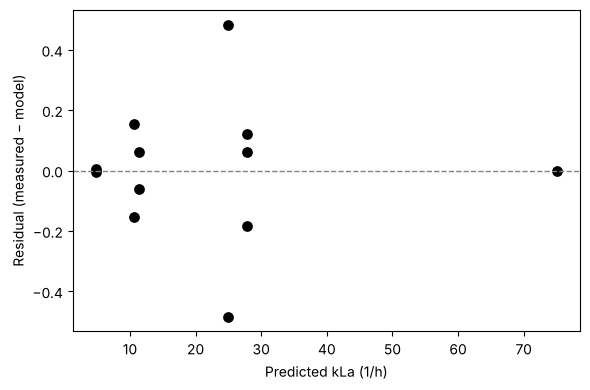

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(model["fitted"], model["resid"], s=45, color="black")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel(f"Predicted {RESPONSE_LABEL}")
ax.set_ylabel("Residual (measured − model)")
fig.tight_layout()
plt.show()

## Part 4. Plots and the importance of the interaction

The contour plot shows the $k_La$ your model predicts over the range of agitation and gas flow you tested. Each condition you ran is marked with its number of runs.

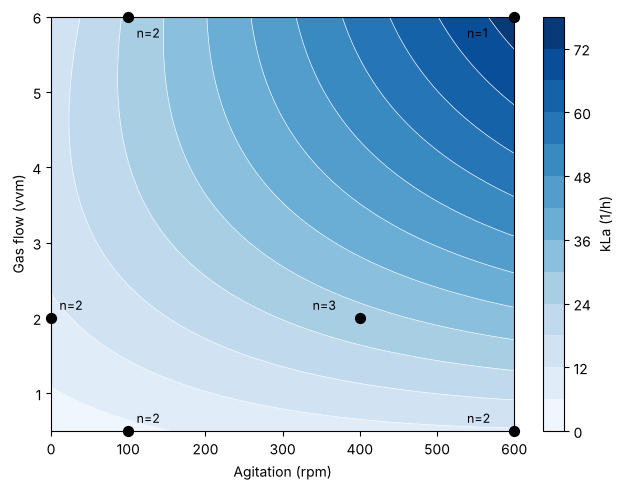

In [7]:
a_lo, a_hi, f_lo, f_hi = A.min(), A.max(), F.min(), F.max()
aa, ff = np.meshgrid(np.linspace(a_lo, a_hi, 120), np.linspace(f_lo, f_hi, 120))
zz = predict(aa.ravel(), ff.ravel()).reshape(aa.shape)

fig, ax = plt.subplots(figsize=(6.5, 5))
cs = ax.contourf(aa, ff, zz, levels=12, cmap="Blues")
ax.contour(aa, ff, zz, levels=12, colors="white", linewidths=0.5)
fig.colorbar(cs, ax=ax, label=RESPONSE_LABEL)
ax.scatter(conditions[FACTOR_A], conditions[FACTOR_F], s=50, color="black", zorder=3, clip_on=False)
for _, row in conditions.iterrows():
    dx = 6 if row[FACTOR_A] <= (a_lo + a_hi) / 2 else -34
    dy = 6 if row[FACTOR_F] <= (f_lo + f_hi) / 2 else -15
    ax.annotate(f"n={int(row['size'])}", (row[FACTOR_A], row[FACTOR_F]), textcoords="offset points",
                xytext=(dx, dy), fontsize=9)
ax.set_xlabel(A_LABEL)
ax.set_ylabel(F_LABEL)
fig.tight_layout()
plt.show()

**The interaction.** The interaction term $\beta_5 AF$ means the effect of agitation depends on the gas flow. The left plot shows your model's $k_La$ against agitation at your lowest and highest gas flow, with your measured averages as points. If there were no interaction, the two lines would be parallel: raising agitation would increase $k_La$ by the same amount at any gas flow. The right plot shows the same model fitted without the interaction term, which forces the lines to be parallel. Compare how well each one follows your measurements.

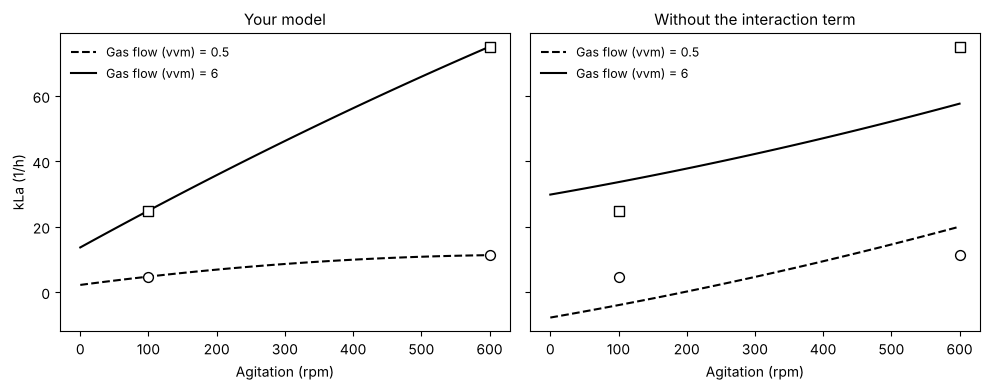

Raising agitation from 0 to 600 rpm changes kLa by +9.1 at 0.5 vvm but by +61.4 at 6 vvm.
Without the interaction term, R² falls from 0.9999 to 0.8109.


In [8]:
no_af = fit([t for t in model["terms"] if t != "AF"]) if "AF" in model["terms"] else None
a_line = np.linspace(a_lo, a_hi, 100)
panels = [(model, "Your model")] + ([(no_af, "Without the interaction term")] if no_af else [])
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4), sharey=True, squeeze=False)
for ax, (r, title) in zip(axes[0], panels):
    for f_val, style, marker in [(f_lo, "--", "o"), (f_hi, "-", "s")]:
        ax.plot(a_line, predict(a_line, np.full_like(a_line, f_val), r), style, color="black",
                label=f"{F_LABEL} = {f_val:g}")
        pts = conditions[np.isclose(conditions[FACTOR_F], f_val)]
        ax.scatter(pts[FACTOR_A], pts["mean"], marker=marker, s=50, facecolor="white", edgecolor="black", zorder=3)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(A_LABEL)
    ax.legend(frameon=False, fontsize=9)
axes[0][0].set_ylabel(RESPONSE_LABEL)
fig.tight_layout()
plt.show()

gain_lo = (predict(a_hi, f_lo) - predict(a_lo, f_lo))[0]
gain_hi = (predict(a_hi, f_hi) - predict(a_lo, f_hi))[0]
if no_af:
    print(f"Raising agitation from {a_lo:g} to {a_hi:g} rpm changes kLa by {gain_lo:+.3g} at {f_lo:g} vvm "
          f"but by {gain_hi:+.3g} at {f_hi:g} vvm.")
    print(f"Without the interaction term, R² falls from {model['r2']:.4f} to {no_af['r2']:.4f}.")
else:
    print(f"Your chosen model has no interaction term, so the lines are parallel: raising agitation from {a_lo:g} "
          f"to {a_hi:g} rpm changes kLa by {gain_lo:+.3g} at every gas flow.")